# 3.8_scanner_drift 扫描仪漂移 — sub-01 ses-test

低频漂移与神经低频信号混合，滤波会影响任务和连接。

预先定义秒/Hz截止，在原时间轴用联合 GLM 放入 DCT+confounds；已有 fMRIPrep cosine 与再次 high-pass 不重复添加。

真实输入、处理前后、可复用关键代码、可视化与量化均在下面。两次采集仅教学few-shot，不能确定最优方法。

**限制：** DCT 0.008Hz 为示例参数，非全局推荐；任务响应保真未测。

In [1]:
from pathlib import Path
import sys, os, importlib.util, json, inspect
ROOT = Path(os.environ["FMRI_REFERENCE_ROOT"]).resolve() if "FMRI_REFERENCE_ROOT" in os.environ else next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/"fmri_reference"/"core.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from repository or set FMRI_REFERENCE_ROOT")
sys.path.insert(0, str(ROOT))
from fmri_reference.core import load_sample
spec = importlib.util.spec_from_file_location("category_reference", ROOT / "03_artifacts_quality_control/3.8_scanner_drift/src/reference.py")
reference = importlib.util.module_from_spec(spec); spec.loader.exec_module(reference)
SESSION = "test"
sample = load_sample(ROOT, SESSION)
print("REAL INPUT:", sample["path"])
print(json.dumps(sample["geometry"], indent=2))
print({k:v for k,v in sample["timing"].items() if k != "onsets_seconds"})
print("before mean/std:", sample["signals"].mean(), sample["signals"].std(ddof=1))


/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


REAL INPUT: /Users/liuxiang/fMRI-preprocess/standard-reference/data/ds000114/sub-01/ses-test/func/sub-01_ses-test_task-fingerfootlips_bold.nii.gz
{
  "shape": [
    64,
    64,
    30,
    184
  ],
  "orientation": [
    "L",
    "A",
    "S"
  ],
  "spacing_mm": [
    3.999999951454272,
    4.000000086623366,
    3.9999749144565446
  ],
  "qform_code": 1,
  "sform_code": 1,
  "qform_sform_disagree": false,
  "affine_ras_mm": [
    [
      -3.9947142601013184,
      -0.20423313975334167,
      0.022935329005122185,
      130.64169311523438
    ],
    [
      -0.205448716878891,
      3.982606887817383,
      -0.3108908534049988,
      -97.47322845458984
    ],
    [
      0.006958197336643934,
      0.31165990233421326,
      3.9878089427948,
      -80.64657592773438
    ],
    [
      0.0,
      0.0,
      0.0,
      1.0
    ]
  ]
}
{'tr_seconds': 2.5, 'sampling_hz': 0.4, 'nyquist_hz': 0.2, 'n_volumes': 184, 'sample_span_seconds': 457.5, 'nominal_duration_seconds': 460.0}
before mean/

## 关键函数与执行

所有源码可追踪。配准/生理/组织输入不存在时，不生成虚构校正结果。

In [2]:
print(inspect.getsource(reference.apply))

def regress(x,confounds=None,keep=None,drift=None,min_dof=5):
    x=timeseries(x);n=len(x)
    keep=np.ones(n,bool) if keep is None else np.asarray(keep)
    if keep.shape!=(n,) or keep.dtype!=bool:raise ValueError('keep must be boolean original-time mask')
    columns=[np.ones((n,1))]
    for c in [confounds,drift]:
        if c is not None:
            c=np.asarray(c,float)
            if c.ndim!=2 or len(c)!=n or not np.isfinite(c).all():raise ValueError('Finite confounds must match original time axis')
            columns.append(c)
    design=np.column_stack(columns);rank=int(np.linalg.matrix_rank(design[keep])) if keep.any() else 0
    dof=int(keep.sum())-rank
    if dof<min_dof:raise ValueError('Too few residual algebraic degrees of freedom')
    beta=np.linalg.lstsq(design[keep],x[keep],rcond=None)[0]
    residual=x[keep]-design[keep]@beta
    return residual,{'rank':rank,'retained':int(keep.sum()),'algebraic_dof':dof,'original_indices':np.flatnonzero(keep).tolist()}



/Users/liuxiang/fMRI-preprocess/standard-reference/fmri_reference/demo.py:89: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  other=nisignal.clean(x,detrend=True,standardize=False,low_pass=None,high_pass=.008,t_r=tr)


{
  "input": "data/ds000114/sub-01/ses-test/func/sub-01_ses-test_task-fingerfootlips_bold.nii.gz",
  "session": "test",
  "kind": "drift",
  "tr_seconds": 2.5,
  "n_input": 184,
  "feature_scope": "128 deterministic voxels from estimated EPI mask, not full brain",
  "before": {
    "shape": [
      184,
      128
    ],
    "mean_abs": 1195.394276494565,
    "median_sample_std": 48.296438755295526,
    "q01": 266.0,
    "q99": 1743.4700000000048
  },
  "production_pipeline": "NOT_RUN",
  "scientific_best_method": "INSUFFICIENT_EVIDENCE",
  "regression": {
    "rank": 8,
    "retained": 184,
    "algebraic_dof": 176,
    "original_indices": [
      0,
      1,
      2,
      3,
      4,
      5,
      6,
      7,
      8,
      9,
      10,
      11,
      12,
      13,
      14,
      15,
      16,
      17,
      18,
      19,
      20,
      21,
      22,
      23,
      24,
      25,
      26,
      27,
      28,
      29,
      30,
      31,
      32,
      33,
      34,
      35,


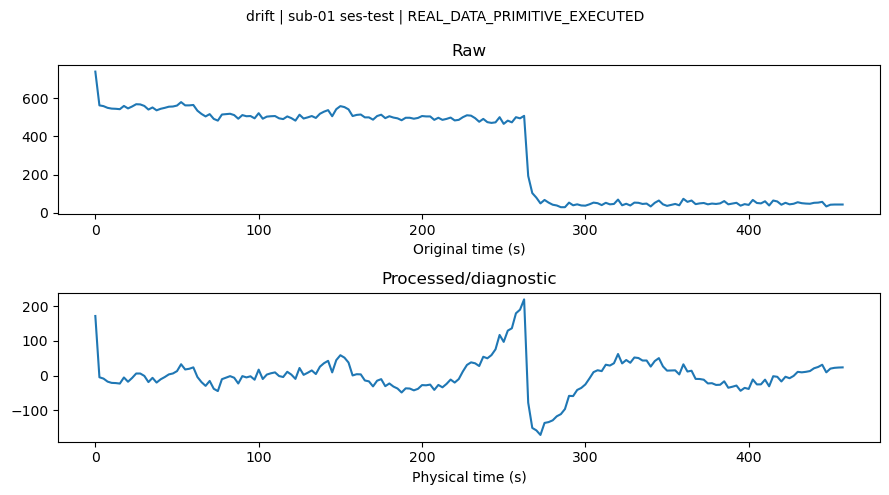

In [3]:
metrics, fig = reference.demonstrate(ROOT, SESSION, variant=0, outdir=ROOT/"03_artifacts_quality_control/3.8_scanner_drift/results/test")
print(json.dumps(metrics, indent=2))
from IPython.display import display
display(fig)
import matplotlib.pyplot as plt
plt.close(fig)

## 常见错误与阻止机制

以下故意提供不满足科学前提的输入。报错是负对照，不是处理失败被掩盖。

In [4]:
try:
    reference.error_example("drift")
except (ValueError, FileNotFoundError) as e:
    print("EXPECTED REJECTION:", type(e).__name__, str(e))
else:
    raise AssertionError("Invalid scientific input was accepted")

EXPECTED REJECTION: ValueError Invalid high-pass/Nyquist


## 解释与后续验证

数值不变性/投影正交性只验证实现数学性质。更低DVARS、更高tSNR、更低配准目标值不是神经信号保真证明。正式推荐需同数据、固定参数、跨受试者的独立下游证据。详见本小类README、references和根目录验证报告。